# A machine-learning emulator for GALFORM

Each GALFORM run on COLIBRE-L100m6 takes hours. An **emulator** is a cheap stand-in for the model: we train it on a set of runs, and it then predicts the result for *any* parameter values in a fraction of a second. That makes it possible to explore the parameter space, or fit to observations, without running GALFORM thousands of times.

Here we emulate the **z = 0 SDSS-r luminosity function (LF)** as a function of the three SN feedback parameters:

| Parameter | What it does | lc16 value | Range in the design |
|---|---|---|---|
| `alphahot` | slope of the mass loading, $\beta = (V_c / V_{\rm hot})^{-\alpha_{\rm hot}}$ | 3.2 | 2.0 – 4.5 |
| `vhot` (`vhotdisk` = `vhotburst`) | normalisation of the mass loading | 320 km/s | 200 – 450 |
| `alpha_reheat` | how fast ejected gas returns, $t_{\rm return} = t_{\rm dyn} / \alpha_{\rm reheat}$ | 0.64 | 0.3 – 1.5 (log-uniform) |

The steps are:
1. Look at the 50 parameter sets (the *design*).
2. Read the 50 LFs that GALFORM produced.
3. Train a Gaussian process on 40 runs.
4. Test it on the other 10, and on the 7 `fb_` runs.
5. Use it to see how each parameter changes the LF.

**Kernel:** this notebook needs the **Python 3.12 (ML)** kernel (top right of the notebook), which has numpy, matplotlib, scipy and scikit-learn.

In [1]:
import glob

import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

ROOT = "/cosma5/data/durham/dc-lock1"
SIM, IZ = "COLIBRE-L100m6", "iz127"
N_TRAIN = 40  # runs 0-39 train the emulator, runs 40-49 test it

NAMES = ["alphahot", "vhot", "alpha_reheat"]
FID = np.array([3.2, 320.0, 0.64])  # lc16

# the fb_ runs, which change one parameter at a time from lc16
FB_RUNS = {
    "fid": FID,
    "alphahot2.2": [2.2, 320, 0.64], "alphahot4.2": [4.2, 320, 0.64],
    "vhot250": [3.2, 250, 0.64], "vhot400": [3.2, 400, 0.64],
    "alpha_reheat0.32": [3.2, 320, 0.32], "alpha_reheat1.28": [3.2, 320, 1.28],
}

50 runs
first 5 rows:
 [[2.2565e+00 2.7542e+02 1.3094e+00]
 [3.2738e+00 2.3208e+02 5.0160e-01]
 [3.0113e+00 3.1521e+02 3.1480e-01]
 [4.4835e+00 3.8247e+02 1.3249e+00]
 [3.9719e+00 3.9665e+02 6.2930e-01]]


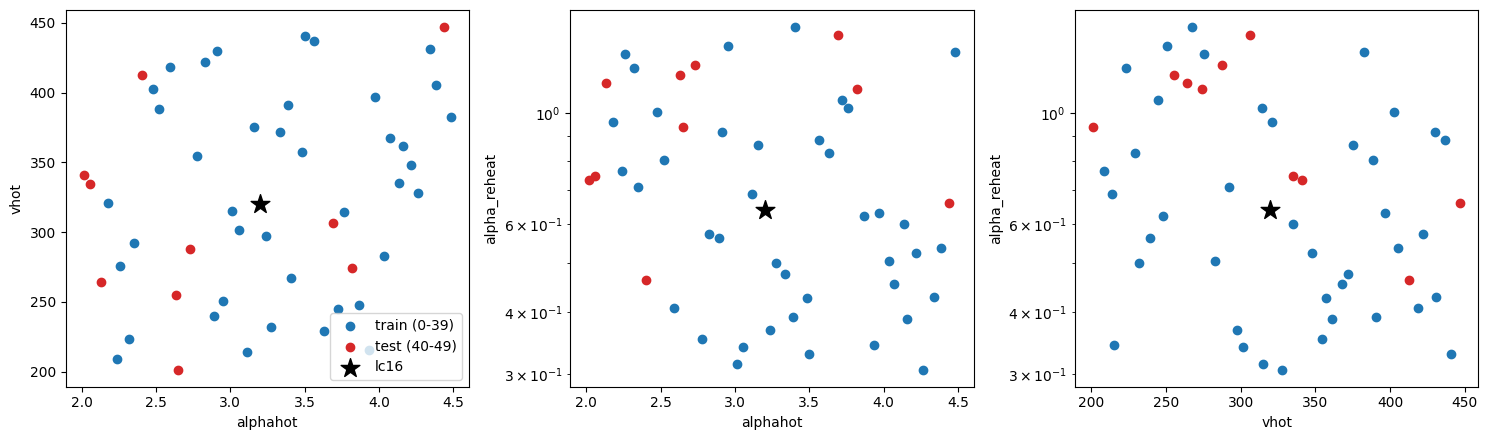

In [2]:
design = np.loadtxt(f"{ROOT}/emu_design.csv", delimiter=",", skiprows=1)
run_ids = design[:, 0].astype(int)
params = design[:, 1:]  # columns: alphahot, vhot, alpha_reheat
print(f"{len(params)} runs")
print("first 5 rows:\n", params[:5])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    ax.scatter(params[:N_TRAIN, a], params[:N_TRAIN, b], color="C0", label="train (0-39)")
    ax.scatter(params[N_TRAIN:, a], params[N_TRAIN:, b], color="C3", label="test (40-49)")
    ax.scatter(FID[a], FID[b], color="k", marker="*", s=200, label="lc16")
    ax.set_xlabel(NAMES[a])
    ax.set_ylabel(NAMES[b])
    if b == 2:
        ax.set_yscale("log")
axes[0].legend()
plt.tight_layout()
plt.show()

## 2. The luminosity functions

Each run has 16 subvolumes. Each subvolume's `gal.lf` is already divided by its own volume, so the LF of the run is the mean over the subvolumes.

In `gal.lf`, column 0 is the magnitude, followed by 4 columns per band (no dust, error, with dust, error). SDSS-r is band 14, so the LF with dust is column `1 + 4*13 + 2`.

emu LFs: (50, 84) (runs, magnitude bins)
fb_ LFs: (7, 84)


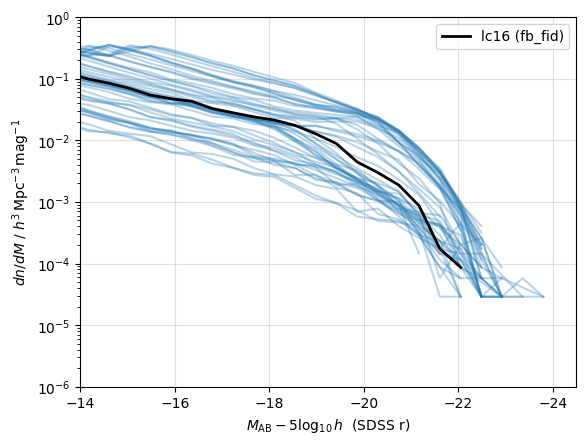

In [3]:
COL = 1 + 4 * 13 + 2


def read_lf(folder):
    # mean LF over the subvolumes of one run
    files = glob.glob(f"{ROOT}/{folder}/{SIM}/lc16/{IZ}/ivol*/gal.lf")
    data = [np.loadtxt(f) for f in files]
    return data[0][:, 0], np.mean([d[:, COL] for d in data], axis=0)


mag_all, _ = read_lf("emu_000")
lfs = np.array([read_lf(f"emu_{i:03d}")[1] for i in run_ids])
fb_lfs = np.array([read_lf(f"fb_{name}")[1] for name in FB_RUNS])
print("emu LFs:", lfs.shape, "(runs, magnitude bins)")
print("fb_ LFs:", fb_lfs.shape)

for phi in lfs:
    ok = phi > 0
    plt.plot(mag_all[ok], phi[ok], color="C0", alpha=0.3)
ok = fb_lfs[0] > 0
plt.plot(mag_all[ok], fb_lfs[0][ok], color="k", lw=2, label="lc16 (fb_fid)")
plt.yscale("log")
plt.xlim(-14, -24.5)
plt.ylim(1e-6, 1)
plt.xlabel(r"$M_{\rm AB} - 5\log_{10} h$  (SDSS r)")
plt.ylabel(r"$dn/dM\ /\ h^{3}\,{\rm Mpc}^{-3}\,{\rm mag}^{-1}$")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

In [4]:
MAG_RANGE = (-23.5, -16)

use = (mag_all >= MAG_RANGE[0]) & (mag_all <= MAG_RANGE[1])
use &= (lfs > 0).all(axis=0) & (fb_lfs > 0).all(axis=0)
mag = mag_all[use]
y = np.log10(lfs[:, use])  # what the emulator learns: one row per run
y_fb = np.log10(fb_lfs[:, use])
print(f"{len(mag)} magnitude bins, from {mag.max():.2f} to {mag.min():.2f}")

# which run has the fewest bright galaxies, and so limits the range?
brightest = [mag_all[phi > 0].min() for phi in lfs]
worst = int(np.argmax(brightest))
print(f"run {worst} has no galaxies brighter than {brightest[worst]:.2f}; its parameters are {params[worst]}")

12 magnitude bins, from -16.36 to -21.17
run 49 has no galaxies brighter than -21.17; its parameters are [  2.4045 412.58     0.4622]


In [5]:
LOW = np.array([2.0, 200.0, np.log10(0.3)])
HIGH = np.array([4.5, 450.0, np.log10(1.5)])


def scale(p):
    # map parameter sets (alphahot, vhot, alpha_reheat) onto the unit cube
    p = np.array(p, dtype=float).reshape(-1, 3).copy()
    p[:, 2] = np.log10(p[:, 2])
    return (p - LOW) / (HIGH - LOW)


x = scale(params)
print("scaled ranges:", x.min(axis=0).round(2), "to", x.max(axis=0).round(2))
print("lc16 scaled:", scale(FID).round(2))

scaled ranges: [0.01 0.01 0.01] to [0.99 0.99 0.99]
lc16 scaled: [[0.48 0.48 0.47]]


In [6]:
kernel = (ConstantKernel(1.0) * RBF([0.5, 0.5, 0.5], length_scale_bounds=(1e-2, 1e2))
          + WhiteKernel(1e-3, noise_level_bounds=(1e-6, 1e-1)))
gp = GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp.fit(x[:N_TRAIN], y[:N_TRAIN])

print("fitted kernel:", gp.kernel_)
length_scales = gp.kernel_.k1.k2.length_scale
for name, ls in zip(NAMES, length_scales):
    print(f"  length scale for {name:13s} {ls:.2f}")

fitted kernel: 1.25**2 * RBF(length_scale=[0.36, 0.883, 1.2]) + WhiteKernel(noise_level=0.0143)
  length scale for alphahot      0.36
  length scale for vhot          0.88
  length scale for alpha_reheat  1.20


## 5. Testing the emulator

The emulator has never seen runs 40–49 or the `fb_` runs, so comparing its predictions with GALFORM tells us how accurate it really is.

The error is in dex: 0.1 dex is a 26% difference in $\phi$, 0.3 dex a factor of 2.

test runs 40-49: rms error 0.105 dex, worst 0.685 dex
fb_ runs:        rms error 0.075 dex, worst 0.322 dex


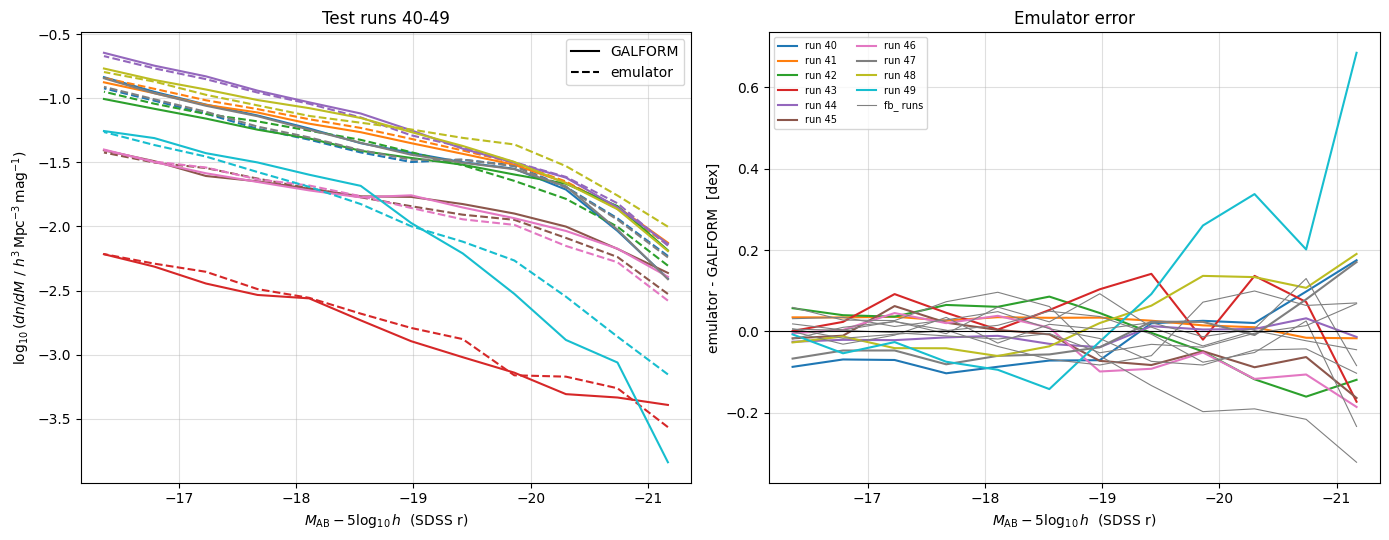

In [7]:
pred_test = gp.predict(x[N_TRAIN:])
pred_fb = gp.predict(scale(list(FB_RUNS.values())))
err_test = pred_test - y[N_TRAIN:]
err_fb = pred_fb - y_fb


def rms(e):
    return np.sqrt(np.mean(e**2))


print(f"test runs 40-49: rms error {rms(err_test):.3f} dex, worst {np.abs(err_test).max():.3f} dex")
print(f"fb_ runs:        rms error {rms(err_fb):.3f} dex, worst {np.abs(err_fb).max():.3f} dex")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for k in range(len(pred_test)):
    axes[0].plot(mag, y[N_TRAIN + k], color=f"C{k}")
    axes[0].plot(mag, pred_test[k], color=f"C{k}", ls="--")
    axes[1].plot(mag, err_test[k], color=f"C{k}", label=f"run {run_ids[N_TRAIN + k]}")
for k in range(len(pred_fb)):
    axes[1].plot(mag, err_fb[k], color="grey", lw=0.8)
axes[0].plot([], [], "k-", label="GALFORM")
axes[0].plot([], [], "k--", label="emulator")
axes[0].set_ylabel(r"$\log_{10}(dn/dM\ /\ h^{3}\,{\rm Mpc}^{-3}\,{\rm mag}^{-1})$")
axes[0].set_title("Test runs 40-49")
axes[0].legend()
axes[1].plot([], [], color="grey", lw=0.8, label="fb_ runs")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_ylabel("emulator - GALFORM  [dex]")
axes[1].set_title("Emulator error")
axes[1].legend(fontsize=7, ncol=2)
for ax in axes:
    ax.set_xlabel(r"$M_{\rm AB} - 5\log_{10} h$  (SDSS r)")
    ax.set_xlim(mag.max() + 0.2, mag.min() - 0.2)  # fainter on the left
    ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()

### Error per run

Which runs does the emulator find hardest? Runs near the edges of the design are usually worst, because the GP has training runs on one side only.

In [8]:
print(" run  alphahot   vhot  alpha_reheat  rms error [dex]")
for k in range(len(pred_test)):
    p = params[N_TRAIN + k]
    print(f"{run_ids[N_TRAIN + k]:4d}  {p[0]:8.2f}  {p[1]:5.0f}  {p[2]:12.2f}  {rms(err_test[k]):.3f}")
print()
for name, e in zip(FB_RUNS, err_fb):
    print(f"fb_{name:18s} {rms(e):.3f}")

 run  alphahot   vhot  alpha_reheat  rms error [dex]
  40      2.01    341          0.73  0.085
  41      2.63    255          1.19  0.028
  42      2.73    288          1.25  0.082
  43      4.44    447          0.66  0.091
  44      2.13    264          1.14  0.022
  45      3.82    274          1.12  0.070
  46      3.69    307          1.43  0.084
  47      2.06    335          0.75  0.071
  48      2.65    201          0.94  0.090
  49      2.40    413          0.46  0.248

fb_fid                0.059
fb_alphahot2.2        0.030
fb_alphahot4.2        0.048
fb_vhot250            0.052
fb_vhot400            0.075
fb_alpha_reheat0.32   0.038
fb_alpha_reheat1.28   0.150


## 6. Using the emulator

Now we can predict the LF for any parameters inside the design range, almost instantly. `return_std=True` also gives the GP's own estimate of its uncertainty (1σ, in dex).

Try changing the values in `predict_lf(...)` below.

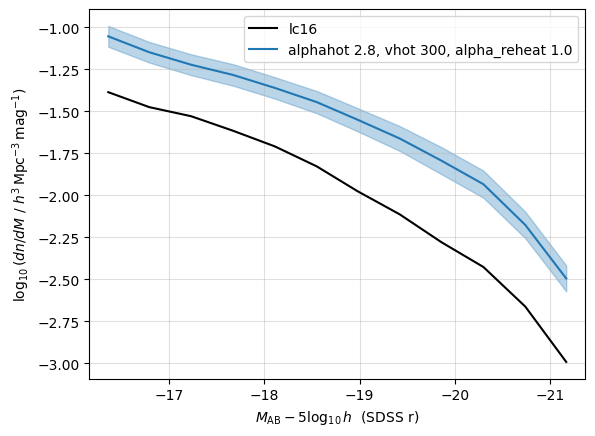

In [9]:
def predict_lf(alphahot, vhot, alpha_reheat):
    # emulated log10(phi) and its 1-sigma uncertainty, in each magnitude bin
    mean, std = gp.predict(scale([alphahot, vhot, alpha_reheat]), return_std=True)
    return mean[0], std[0]


mean, std = predict_lf(2.8, 300, 1.0)
mean_fid, _ = predict_lf(*FID)
plt.plot(mag, mean_fid, "k", label="lc16")
plt.plot(mag, mean, "C0", label="alphahot 2.8, vhot 300, alpha_reheat 1.0")
plt.fill_between(mag, mean - std, mean + std, color="C0", alpha=0.3)
plt.xlim(mag.max() + 0.2, mag.min() - 0.2)
plt.xlabel(r"$M_{\rm AB} - 5\log_{10} h$  (SDSS r)")
plt.ylabel(r"$\log_{10}(dn/dM\ /\ h^{3}\,{\rm Mpc}^{-3}\,{\rm mag}^{-1})$")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

### Sensitivity: what does each parameter do?

Move one parameter across its whole range while holding the other two at their lc16 values, and plot the change relative to lc16. Shaded bands are the emulator's 1σ uncertainty.

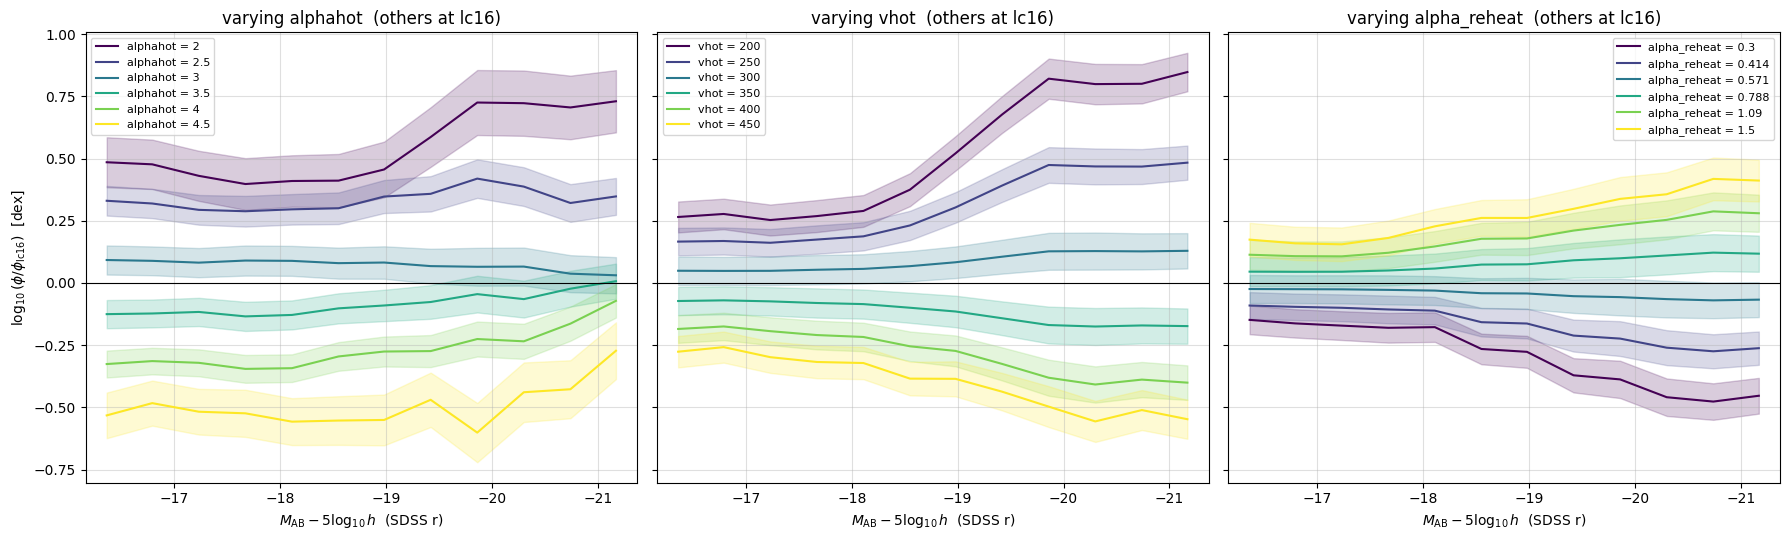

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for j, ax in enumerate(axes):
    if j == 2:
        values = np.geomspace(0.3, 1.5, 6)
    else:
        values = np.linspace(LOW[j], HIGH[j], 6)
    colours = plt.cm.viridis(np.linspace(0, 1, len(values)))
    for v, c in zip(values, colours):
        p = FID.copy()
        p[j] = v
        mean, std = predict_lf(*p)
        ax.plot(mag, mean - mean_fid, color=c, label=f"{NAMES[j]} = {v:.3g}")
        ax.fill_between(mag, mean - mean_fid - std, mean - mean_fid + std, color=c, alpha=0.2)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel(r"$M_{\rm AB} - 5\log_{10} h$  (SDSS r)")
    ax.set_xlim(mag.max() + 0.2, mag.min() - 0.2)
    ax.set_title(f"varying {NAMES[j]}  (others at lc16)")
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"$\log_{10}(\phi / \phi_{\rm lc16})$  [dex]")
plt.tight_layout()
plt.show()

## 7. How many training runs do we need?

Each GALFORM run is expensive, so it's worth knowing whether more runs would make the emulator noticeably better. Here we train it on **10, 20, 30 and 40** runs and test every version on the **same 10 test runs (40–49)**, plus the 7 `fb_` runs. The training runs are always taken from runs 0–39, so the test runs are never seen in training.

With few training runs, the result depends a lot on *which* runs are picked. So for 10, 20 and 30 we repeat the training 5 times, each with a different random choice of runs, and show the average and the spread. For 40 there is only one choice (all of runs 0–39).

This cell fits 16 emulators, so it takes a few minutes.

In [ ]:
N_SIZES = [10, 20, 30, 40]
N_REPEATS = 5
rng = np.random.default_rng(1)

results = {}
for n in N_SIZES:
    results[n] = []
    repeats = 1 if n == N_TRAIN else N_REPEATS  # only one way to pick all 40
    for r in range(repeats):
        train = rng.choice(N_TRAIN, size=n, replace=False)
        gp_n = GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=10, random_state=0)
        gp_n.fit(x[train], y[train])
        err_n = gp_n.predict(x[N_TRAIN:]) - y[N_TRAIN:]
        err_fb_n = gp_n.predict(scale(list(FB_RUNS.values()))) - y_fb
        results[n].append((rms(err_n), rms(err_fb_n), np.sqrt(np.mean(err_n**2, axis=0))))
    test = [res[0] for res in results[n]]
    fb = [res[1] for res in results[n]]
    print(f"{n:2d} training runs: rms error on test runs {np.mean(test):.3f} dex "
          f"(range {min(test):.3f}-{max(test):.3f}), on fb_ runs {np.mean(fb):.3f} dex")

10 training runs: rms error on test runs 0.182 dex (range 0.124-0.236), on fb_ runs 0.146 dex
20 training runs: rms error on test runs 0.128 dex (range 0.091-0.171), on fb_ runs 0.098 dex
30 training runs: rms error on test runs 0.112 dex (range 0.105-0.123), on fb_ runs 0.084 dex
40 training runs: rms error on test runs 0.105 dex (range 0.105-0.105), on fb_ runs 0.075 dex


### Plotting the learning curve

**Left:** the average error against the number of training runs, with bars showing the best and worst of the 5 random choices. If the curve is still falling steeply at 40, more runs would help; if it has flattened, extra runs would add little.

**Right:** the error in each magnitude bin on the test runs, for each number of training runs. This shows *where* the extra runs help most.

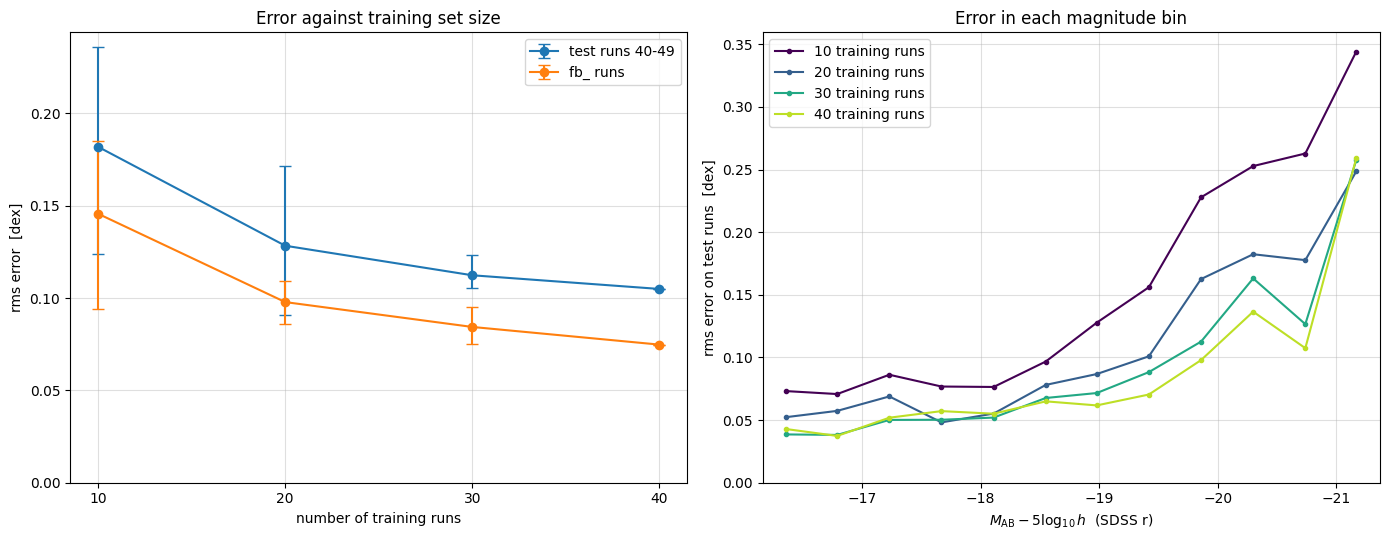

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for i, label in ((0, "test runs 40-49"), (1, "fb_ runs")):
    mean = [np.mean([res[i] for res in results[n]]) for n in N_SIZES]
    low = [mean[k] - min(res[i] for res in results[n]) for k, n in enumerate(N_SIZES)]
    high = [max(res[i] for res in results[n]) - mean[k] for k, n in enumerate(N_SIZES)]
    axes[0].errorbar(N_SIZES, mean, yerr=[low, high], marker="o", capsize=4, label=label)
axes[0].set_xlabel("number of training runs")
axes[0].set_ylabel("rms error  [dex]")
axes[0].set_xticks(N_SIZES)
axes[0].set_ylim(bottom=0)
axes[0].set_title("Error against training set size")
axes[0].legend()

colours = plt.cm.viridis(np.linspace(0, 0.9, len(N_SIZES)))
for n, c in zip(N_SIZES, colours):
    per_bin = np.mean([res[2] for res in results[n]], axis=0)
    axes[1].plot(mag, per_bin, color=c, marker="o", ms=3, label=f"{n} training runs")
axes[1].set_xlabel(r"$M_{\rm AB} - 5\log_{10} h$  (SDSS r)")
axes[1].set_xlim(mag.max() + 0.2, mag.min() - 0.2)  # fainter on the left
axes[1].set_ylabel("rms error on test runs  [dex]")
axes[1].set_ylim(bottom=0)
axes[1].set_title("Error in each magnitude bin")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()